# SANVIA Stage 1: Reproducible Multi-Task Mammography Backbone Benchmark

Compares six ImageNet-pretrained CNN backbones (ResNet50, DenseNet121, InceptionV3, MobileNetV3-Large,
EfficientNet-B4, EfficientNetV2-S) on VinDr-Mammo PNG images. One sample is one breast (CC + MLO).
Tasks: BI-RADS (5 classes) and breast density (4 classes). The two best backbones are selected on **Validation only**;
the official Test split is never used for training, tuning, checkpoint selection or backbone selection.

This notebook only orchestrates the modular code in `src/sanvia`. Set `REPO_DIR` below to the repository location
(clone it into Google Drive or `/content`). Runs are resumable: re-running Section 13 continues interrupted runs.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Section 1 - Google Drive and environment setup

In [2]:
import os
import sys
from pathlib import Path

# Must be set before CUDA is initialised: reduces memory fragmentation for the large EfficientNet inputs.
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

ON_COLAB = "google.colab" in sys.modules
REPO_DIR = Path("/content/drive/MyDrive/SANVIA")   # location of the cloned repository
OVERRIDES = {}        # optional configuration overrides, e.g. {"training": {"num_workers": 2}}
PRETRAINED = True     # ImageNet weights; keep True for the real benchmark
RESUME = True         # continue interrupted runs of identical configuration/dataset/split

if ON_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
if ON_COLAB:
    %pip install -q -r {REPO_DIR}/requirements.txt
    %pip install -q -e {REPO_DIR} --no-deps

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for sanvia (pyproject.toml) ... done


In [4]:
import sys
from pathlib import Path

# Ensure the repository root and its possible 'src' directory are in Python's search path
if 'REPO_DIR' in globals():
    repo_path = str(REPO_DIR)
    src_path = str(REPO_DIR / "src")
    if repo_path not in sys.path:
        sys.path.insert(0, repo_path)
    if src_path not in sys.path:
        sys.path.insert(0, src_path)

import platform
import torch
import torchvision
import pandas as pd
from IPython.display import Image, display

from sanvia.utils.config import config_hash, load_config, save_resolved_config
from sanvia.utils.environment import collect_environment
from sanvia.utils.logging import setup_logging
from sanvia.utils.paths import build_paths, ensure_output_dirs, verify_input_paths
from sanvia.utils.seed import NONDETERMINISM_NOTES, set_global_seed

cfg = load_config(REPO_DIR / "configs", OVERRIDES)
setup_logging(cfg["logging"]["level"])
paths = build_paths(cfg)
verify_input_paths(paths)        # raises a clear error naming every missing path
ensure_output_dirs(paths)

print("Python     :", platform.python_version())
print("PyTorch    :", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA       :", torch.cuda.is_available())
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print(f"GPU        : {props.name}, {props.total_memory / 1024**3:.1f} GB")
    torch.backends.cuda.matmul.allow_tf32 = True      # faster matmuls on Ampere+, negligible effect on accuracy
    torch.backends.cudnn.allow_tf32 = True
    torch.cuda.empty_cache()
else:
    print("WARNING: no GPU detected. Training six backbones on CPU is impractical; select a GPU runtime.")

Python     : 3.13.16
PyTorch    : 2.14.1+cu130
Torchvision: 0.29.1+cu130
CUDA       : True
GPU        : NVIDIA RTX PRO 6000 Blackwell Server Edition, 95.0 GB


## Section 2 - Project configuration

In [5]:
# load_config already validated: seeds consistent, no full-image DVC tracking, no Test evaluation, six backbones.
set_global_seed(cfg["project"]["seed"], cfg["training"]["deterministic"])
save_resolved_config(cfg, paths.reports_dir / "resolved_config.yaml")
CONFIG_HASH = config_hash(cfg)
print("Configuration hash:", CONFIG_HASH)
print("Output directory  :", paths.output_dir)
print("Known sources of nondeterminism:")
for note in NONDETERMINISM_NOTES:
    print(" -", note)

Configuration hash: 3d8a48eaa4a1
Output directory  : /content/drive/MyDrive/VnDir_Mammo/sanvia_outputs
Known sources of nondeterminism:
 - CUDA atomics in some backward kernels can vary between runs even with deterministic flags.
 - Mixed precision (AMP) changes numerical rounding and can differ across GPU models and driver versions.
 - DataLoader worker scheduling is seeded per worker, but augmentation draws depend on worker assignment.
 - Resuming from a checkpoint restores RNG states, but the DataLoader shuffle order of the interrupted epoch is not replayed.
 - Different torch, torchvision, CUDA or cuDNN versions may change results.


## Section 3 - Git initialization and metadata

In [6]:
!git config --global --add safe.directory /content/drive/MyDrive/SANVIA
!cd /content/drive/MyDrive/SANVIA && git config user.email "yanal.university@gmail.com" && git config user.name "Yanal"

In [7]:
from sanvia.mlops.git_metadata import get_git_metadata, reproducibility_statement
from sanvia.utils.io import save_json

git = get_git_metadata(REPO_DIR)
env = collect_environment()
save_json({"git": git, "environment": env}, paths.reports_dir / "environment_and_git.json")
print("Commit :", git["commit"], "| branch:", git["branch"], "| dirty:", git["dirty"])
print(reproducibility_statement(git))
display(pd.Series(env["packages"], name="version").to_frame())

Commit : 667708020cdbb166922a70a3b0925a7281dd9e99 | branch: master | dirty: True
Repository has uncommitted changes: the run is NOT fully reproducible from the commit hash alone.


,version
torch,2.14.1+cu130
torchvision,0.29.1+cu130
numpy,2.4.6
pandas,2.2.3
scikit-learn,1.6.1
pillow,11.3.0
matplotlib,3.10.0
seaborn,0.13.2
pyyaml,6.0.3
mlflow,3.18.0


In [8]:
!git config --global --add safe.directory /content/drive/MyDrive/SANVIA
!cd /content/drive/MyDrive/SANVIA && git config user.email "you@example.com" && git config user.name "Your Name"

## Section 4 - DVC initialization and dataset versioning

DVC tracks only small files (CSVs, manifests, splits). The PNG images are **not** copied or tracked by DVC;
they are verified through a SHA-256 manifest. The manifest detects changes but cannot restore old image versions.

In [9]:
from sanvia.data import pipeline as pl
from sanvia.data.image_indexing import index_png_files
from sanvia.mlops.data_versioning import DVCManager, verify_png_manifest

dvc_cfg = cfg["mlops"]["dvc"]
assert dvc_cfg["track_full_images"] is False

manifest_path = paths.manifests_dir / "png_image_manifest.csv"
if dvc_cfg["verify_image_checksums"] and manifest_path.exists():
    previous = pd.read_csv(manifest_path)
    report = verify_png_manifest(previous, index_png_files(paths.images_dir, cfg["data"]["indexing"]["extension"]),
                                 cfg["data"]["indexing"]["hash_workers"])
    print("Previous manifest verification:", {k: (v if not isinstance(v, list) else len(v)) for k, v in report.items()})
    if not report["identical"]:
        print("WARNING: images differ from the saved manifest; a new dataset id will be created.")

index, png_manifest, dataset_record = pl.index_and_manifest(cfg, paths)
print("Indexed PNG files :", len(png_manifest))
print("Dataset id        :", dataset_record["dataset_id"])
print("PNG manifest hash :", dataset_record["png_manifest_checksum"][:16])
display(png_manifest.head())

2026-11-25 17:48:22,096 | INFO | sanvia.data.image_indexing | Indexed 19998 PNG files (19998 unique stems, 0 duplicated stems)
2026-11-25 18:02:45,240 | INFO | sanvia.mlops.data_versioning | Built PNG manifest with 19998 rows
Indexed PNG files : 19998
Dataset id        : ds-bf41e4d9751ccee3
PNG manifest hash : e6bbdabd55910eb9


,image_id,relative_path,file_size,mtime_ns,sha256,width,height,bit_depth,color_type,header_error
0,2ddfad7286c2b016931ceccd1e2c7bbc,0025a5dc99fd5c742026f0b2b030d3e9/2ddfad7286c2b...,442407,1766136879000000000,80c777c81b24ccce752e76cb6a1d444d8bd0179056447a...,912,1520,8,0,None
1,451562831387e2822923204cf8f0873e,0025a5dc99fd5c742026f0b2b030d3e9/451562831387e...,366322,1766136879000000000,59e1603a7d290fb485b79d99a63ee00b42188a0f06e7fd...,912,1520,8,0,None
2,47c8858666bcce92bcbd57974b5ce522,0025a5dc99fd5c742026f0b2b030d3e9/47c8858666bcc...,444199,1766136879000000000,428f5650afbaaf69fb4dc187680d70f8d8be5722a7c7eb...,912,1520,8,0,None
3,fcf12c2803ba8dc564bf1287c0c97d9a,0025a5dc99fd5c742026f0b2b030d3e9/fcf12c2803ba8...,367476,1766136879000000000,4c432e6cde3c86f60e994769290cf4fdb68ddfb2790992...,912,1520,8,0,None
4,16e58fc1d65fa7587247e6224ee96527,0028fb2c7f0b3a5cb9a80cb0e1cdbb91/16e58fc1d65fa...,449664,1766136879000000000,0de328592c5940d9d4eb7907d7777ab9afa9ddc5c6e725...,912,1520,8,0,None


In [10]:
DVC_ENABLED = dvc_cfg["enabled"]
dvc_status = "disabled"
if DVC_ENABLED:
    try:
        dvc = DVCManager(REPO_DIR, cfg, paths.dvc_remote_dir)   # persistent remote on Google Drive (small files only)
        dvc.ensure_initialized()
        tracked = {}
        if dvc_cfg["track_csv_files"]:
            tracked.update({p.name: p for p in (paths.metadata_csv, paths.breast_annotations_csv, paths.finding_annotations_csv)})
        if dvc_cfg["track_manifests"]:
            tracked.update({"png_image_manifest.csv": manifest_path, "dataset_manifest.json": paths.manifests_dir / "dataset_manifest.json"})
        dvc.stage_files(tracked)
        dvc.push()
        dvc_status = "tracked and pushed; remote in sync" if dvc.remote_in_sync() else "pushed; remote NOT in sync"
    except Exception as exc:       # DVC problems must not corrupt the experiment; they are reported, not hidden
        dvc_status = f"failed: {type(exc).__name__}: {exc}"
print("DVC status:", dvc_status)
print("Remember to `git add data/tracked/*.dvc .dvc dvc.yaml` and commit before training.")

DVC status: failed: CalledProcessError: Command '['dvc', 'add', 'data/tracked/metadata.csv']' returned non-zero exit status 1.
Remember to `git add data/tracked/*.dvc .dvc dvc.yaml` and commit before training.


In [11]:
!cd /content/drive/MyDrive/SANVIA && git add .dvc dvc.yaml data/tracked/*.dvc && git commit -m "Track data with DVC"

fatal: pathspec 'data/tracked/*.dvc' did not match any files


## Section 5 - Data loading and audit

2026-11-25 18:02:53,993 | INFO | sanvia.data.loading | Loaded metadata.csv: shape=(20000, 21)
2026-11-25 18:02:54,011 | INFO | sanvia.data.loading | Loaded breast-level_annotations.csv: shape=(20000, 10)
2026-11-25 18:02:54,030 | INFO | sanvia.data.loading | Loaded finding_annotations.csv: shape=(20486, 16)
Images: 19998 | unreadable: 0 | bit depths: {8: 19998}
Studies: 5000 | unique images: 20000 | studies without 4 images: 0
Missing BI-RADS: 0 | missing density: 0 | unknown labels: {'birads': [], 'density': []}
Image mapping: {'n_annotation_image_ids': 20000, 'n_missing': 2, 'n_ambiguous': 0, 'n_unexpected_png_files': 0, 'n_duplicate_stems': 0}
Duplicate records: 2 | inconsistent breasts (BI-RADS/density): 0 0
Findings: {'n_findings': 20486, 'category_counts': {'No Finding': 18232, 'Mass': 1226, 'Suspicious Calcification': 543, 'Focal Asymmetry': 269, 'Architectural Distortion': 119, 'Asymmetry': 97, 'Suspicious Lymph Node': 57, 'Skin Thickening': 57, 'Nipple Retraction': 37, 'Global

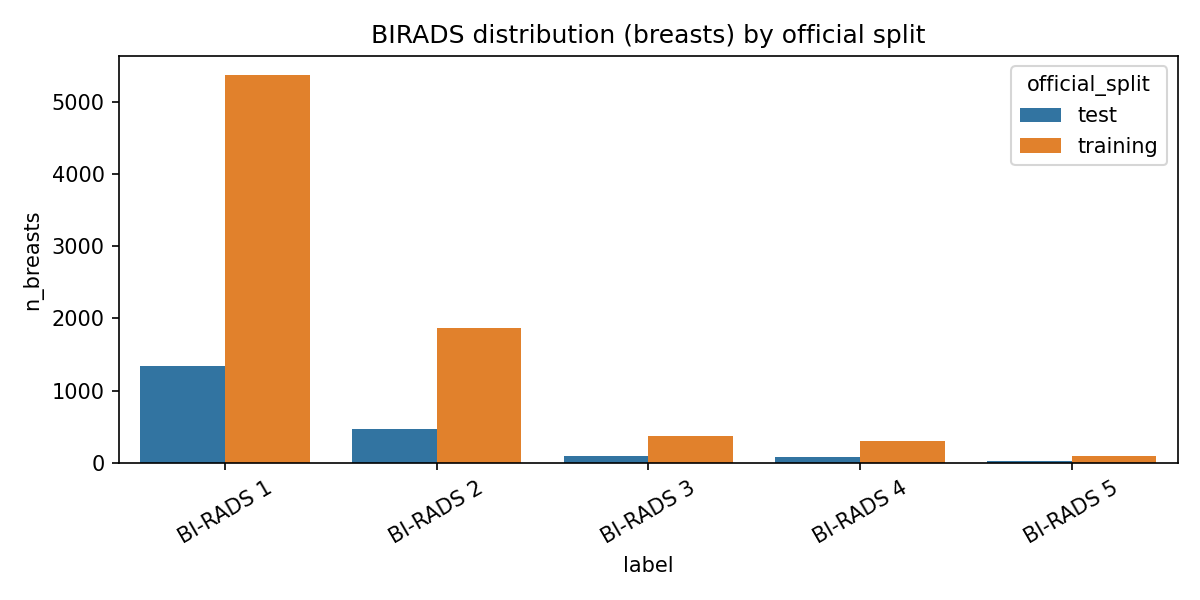

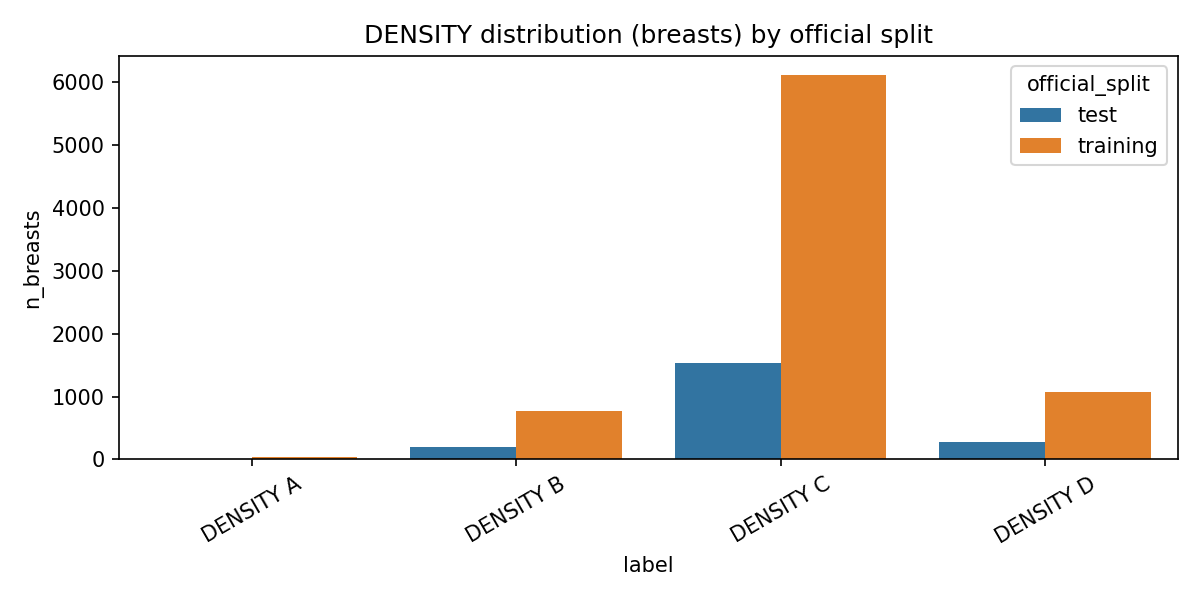

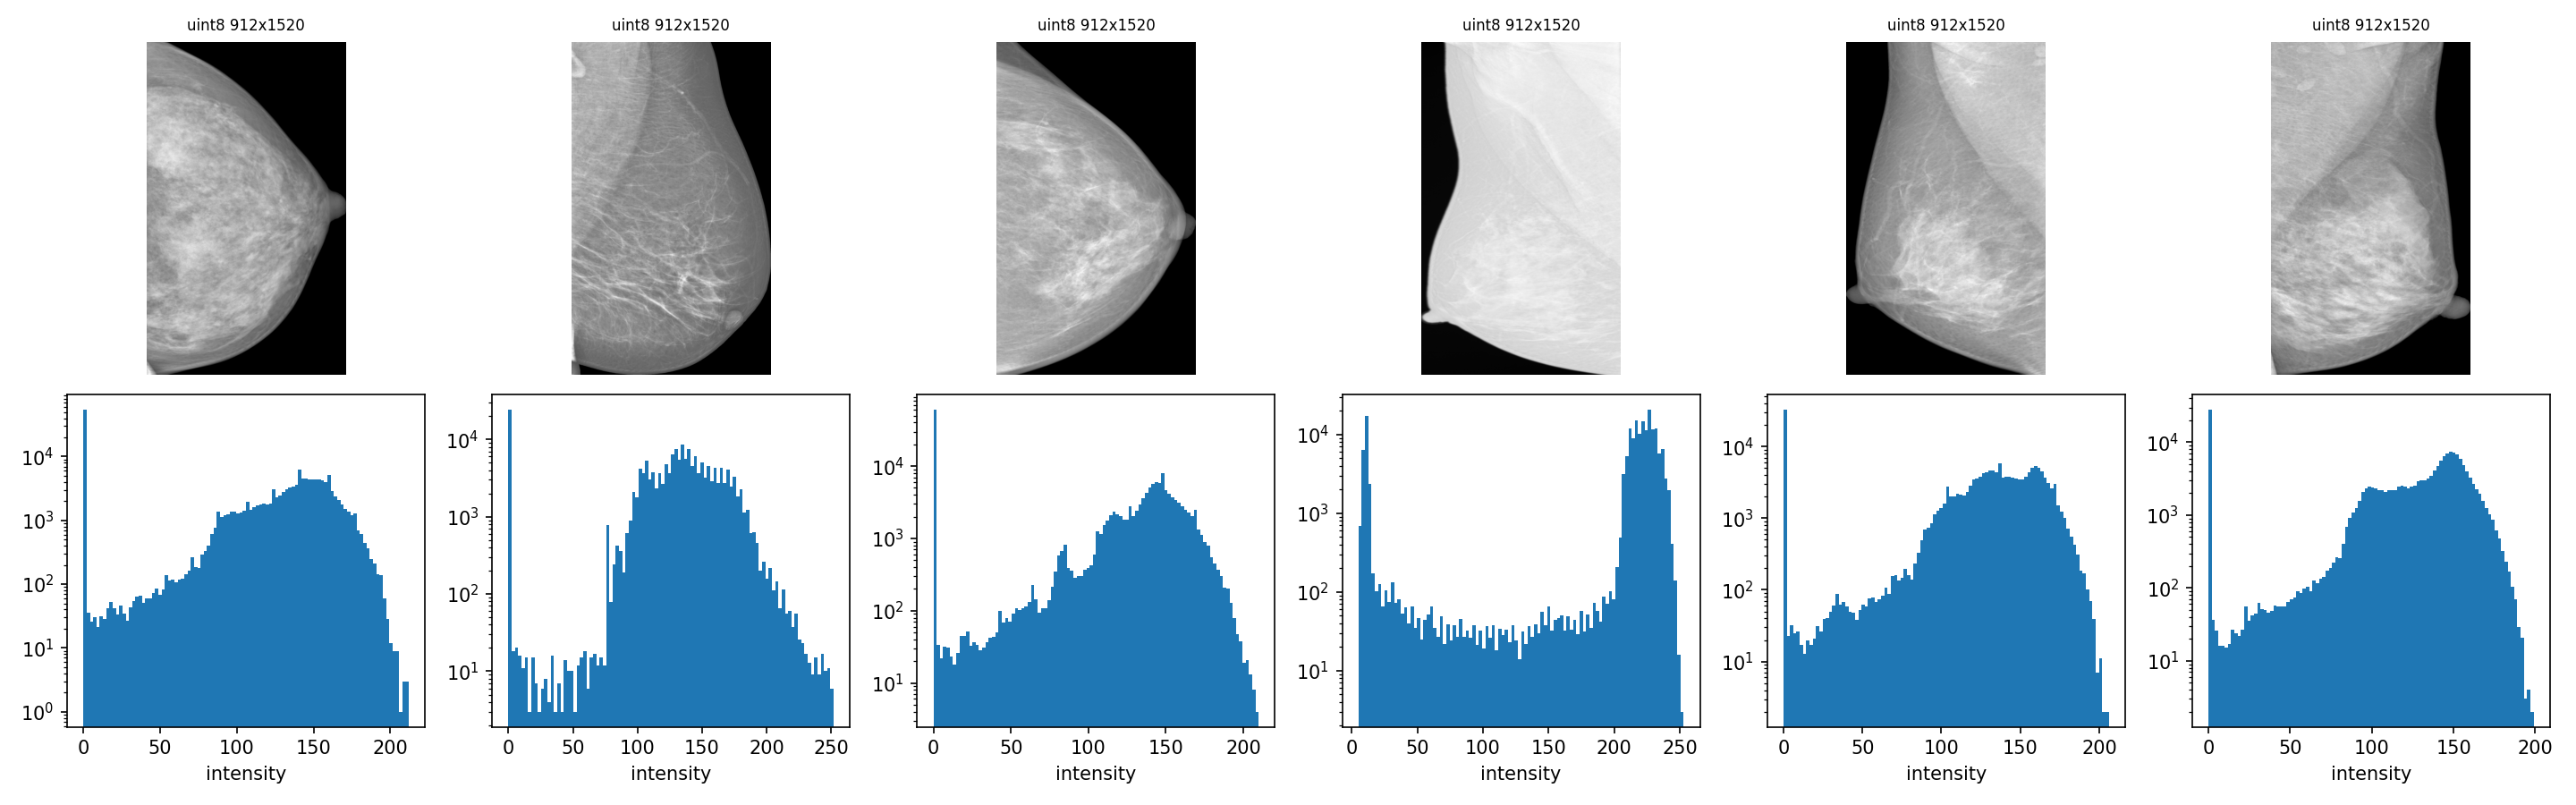

Integrity gate passed.


In [12]:
audit = pl.audit_stage(cfg, paths, index, png_manifest)
s = audit["summary"]
print("Images:", s["images"]["n_images"], "| unreadable:", s["images"]["n_unreadable"], "| bit depths:", s["images"]["bit_depth_counts"])
print("Studies:", s["annotations"]["n_unique_studies"], "| unique images:", s["annotations"]["n_unique_images"],
      "| studies without 4 images:", s["annotations"]["studies_without_four_images"])
print("Missing BI-RADS:", s["annotations"]["birads_missing"], "| missing density:", s["annotations"]["density_missing"],
      "| unknown labels:", s["annotations"]["unknown_labels"])
print("Image mapping:", s["mapping"])
print("Duplicate records:", s["annotations"]["n_duplicate_records"],
      "| inconsistent breasts (BI-RADS/density):", s["annotations"]["n_breasts_birads_inconsistent"], s["annotations"]["n_breasts_density_inconsistent"])
print("Findings:", {k: v for k, v in s["findings"].items() if k != "columns"})
for plot in audit["plots"]:
    display(Image(filename=str(plot)))
if audit["critical_issues"]:
    raise RuntimeError(f"Critical data issues, training blocked: {audit['critical_issues']}")
print("Integrity gate passed.")

## Section 6 - Official split verification and internal Train/Validation split

In [13]:
split = pl.split_stage(cfg, paths, audit)
print("Official split (studies):", split["verification"]["studies_per_official_split"])
print("Split id:", split["split_id"], "| stratification:", split["stratification_level"])
print("Studies  train / validation / official test:", len(split["train_ids"]), len(split["val_ids"]), len(split["test_ids"]))

Official split (studies): {'test': 1000, 'training': 4000}
Split id: split-d2d42a3c7075 | stratification: birads_density_signature_with_rare_merge
Studies  train / validation / official test: 3200 800 1000


## Section 7 - Breast-level sample construction

In [14]:
out = pl.sample_stage(cfg, paths, audit, split)
samples, excluded = out["samples"], out["excluded"]
print("Valid breast samples:", len(samples), "| excluded:", len(excluded))
print(samples["final_split"].value_counts().to_string())
print("Age integration:", out["age_reason"])
if len(excluded):
    print("Exclusion reasons:")
    print(excluded["reasons"].str.split(";").explode().str.split(":").str[0].value_counts().to_string())
display(out["distribution"].pivot_table(index=["task", "class"], columns="final_split", values="count", aggfunc="sum"))
display(samples.head())
if out["issues"]:
    raise RuntimeError(f"Critical sample-construction issues, training blocked: {out['issues']}")
if DVC_ENABLED and dvc_status.startswith("tracked"):
    dvc.stage_files({p.name: p for p in [paths.splits_dir / "final_sample_manifest.csv", paths.splits_dir / "train_studies.csv",
                                         paths.splits_dir / "validation_studies.csv", paths.splits_dir / "official_test_studies.csv",
                                         paths.manifests_dir / "dataset_manifest.json"]})
    dvc.push()

2026-11-25 18:03:11,110 | INFO | sanvia.data.sample_builder | Built 9998 breast samples, excluded 2
Valid breast samples: 9998 | excluded: 2
final_split
train            6399
official_test    2000
validation       1599
Age integration: Age verified via SOP Instance UID (match rate 1.0000).
Exclusion reasons:
reasons
missing_mlo             1
duplicate_cc_records    1
cc_image_missing        1
mlo_image_missing       1


final_split        official_test  train  validation
task    class                                      
all     n_samples           2000   6399        1599
birads  BI-RADS 1           1341   4287        1074
        BI-RADS 2            467   1493         377
        BI-RADS 3             93    301          71
        BI-RADS 4             76    246          59
        BI-RADS 5             23     72          18
density Density A             10     30          10
        Density B            190    609         155
        Density C           1530   4896        1218
        Density D            270    864         216

,sample_id,study_id,laterality,cc_image_id,mlo_image_id,cc_image_path,mlo_image_path,cc_image_relpath,mlo_image_relpath,cc_series_id,...,birads_original,birads_encoded,birads_valid,density_original,density_encoded,density_valid,age,age_missing_flag,official_split,final_split
0,0025a5dc99fd5c742026f0b2b030d3e9_L,0025a5dc99fd5c742026f0b2b030d3e9,L,451562831387e2822923204cf8f0873e,2ddfad7286c2b016931ceccd1e2c7bbc,/content/drive/MyDrive/VnDir_Mammo/images/imag...,/content/drive/MyDrive/VnDir_Mammo/images/imag...,0025a5dc99fd5c742026f0b2b030d3e9/451562831387e...,0025a5dc99fd5c742026f0b2b030d3e9/2ddfad7286c2b...,47d59b788d64eecab165d97471c4131a,...,BI-RADS 1,0,True,DENSITY C,2,True,44.0,0,test,official_test
1,0025a5dc99fd5c742026f0b2b030d3e9_R,0025a5dc99fd5c742026f0b2b030d3e9,R,fcf12c2803ba8dc564bf1287c0c97d9a,47c8858666bcce92bcbd57974b5ce522,/content/drive/MyDrive/VnDir_Mammo/images/imag...,/content/drive/MyDrive/VnDir_Mammo/images/imag...,0025a5dc99fd5c742026f0b2b030d3e9/fcf12c2803ba8...,0025a5dc99fd5c742026f0b2b030d3e9/47c8858666bcc...,47d59b788d64eecab165d97471c4131a,...,BI-RADS 1,0,True,DENSITY C,2,True,44.0,0,test,official_test
2,0028fb2c7f0b3a5cb9a80cb0e1cdbb91_L,0028fb2c7f0b3a5cb9a80cb0e1cdbb91,L,3704f91985dcbc69f6ac2803523d1ecb,7fc1f1bb8bb1a7efaf7104e49c4d8b86,/content/drive/MyDrive/VnDir_Mammo/images/imag...,/content/drive/MyDrive/VnDir_Mammo/images/imag...,0028fb2c7f0b3a5cb9a80cb0e1cdbb91/3704f91985dcb...,0028fb2c7f0b3a5cb9a80cb0e1cdbb91/7fc1f1bb8bb1a...,ff5d6ba6e303628092020e897fcbc9b1,...,BI-RADS 2,1,True,DENSITY C,2,True,51.0,0,training,train
3,0028fb2c7f0b3a5cb9a80cb0e1cdbb91_R,0028fb2c7f0b3a5cb9a80cb0e1cdbb91,R,c4ce68631bf70949570ded31a3c69e60,16e58fc1d65fa7587247e6224ee96527,/content/drive/MyDrive/VnDir_Mammo/images/imag...,/content/drive/MyDrive/VnDir_Mammo/images/imag...,0028fb2c7f0b3a5cb9a80cb0e1cdbb91/c4ce68631bf70...,0028fb2c7f0b3a5cb9a80cb0e1cdbb91/16e58fc1d65fa...,ff5d6ba6e303628092020e897fcbc9b1,...,BI-RADS 2,1,True,DENSITY C,2,True,51.0,0,training,train
4,0034765af074f93ed33d5e8399355caf_L,0034765af074f93ed33d5e8399355caf,L,68f09c18925a66ef2840d4a62f237b31,b664cf1e7c968896144a3a2005cd3eb4,/content/drive/MyDrive/VnDir_Mammo/images/imag...,/content/drive/MyDrive/VnDir_Mammo/images/imag...,0034765af074f93ed33d5e8399355caf/68f09c18925a6...,0034765af074f93ed33d5e8399355caf/b664cf1e7c968...,91de7075b7eb54cc4fc959ef67b9df56,...,BI-RADS 2,1,True,DENSITY C,2,True,37.0,0,training,train


## Section 8 - Preprocessing

Normalisation is derived from the PNG audit (no blind division by 255). Images are letterboxed (aspect ratio preserved,
no center crop), replicated to three channels and ImageNet-normalised. Fitted quantities (class weights, age
imputation/scaling, optional global window) use Train only.

In [15]:
td = pl.make_training_data(cfg, paths, samples, audit, out["age_enabled"], out["age_reason"], out["dataset_record"], split["split_id"])
print("Normalisation:", td.normalizer.to_dict())
print("Audit-based validation:", td.extras["normalization_report"])
print("Class weights BI-RADS:", td.class_weights["birads"].round(3).tolist())
print("Class weights density:", td.class_weights["density"].round(3).tolist())
print("Age branch enabled:", td.age_enabled, "|", td.age_reason)

from sanvia.data.preprocessing import PNGPreprocessor, plot_preprocessing_examples
for size in sorted({b["input_size"] for b in cfg["backbones"]}):
    pre = PNGPreprocessor(size, td.normalizer, cfg["data"]["preprocessing"])
    info = plot_preprocessing_examples(td.train_df, pre, paths.preprocessing_dir / f"preprocessing_{size}.png", n=2)
    display(Image(filename=str(paths.preprocessing_dir / f"preprocessing_{size}.png")))
save_json(info, paths.preprocessing_dir / "last_preprocessing_example_info.json")

Output hidden; open in https://colab.research.google.com to view.

## Section 9 - Dataset and DataLoader creation

In [16]:
from sanvia.models.backbone_factory import get_backbone_spec

spec0 = get_backbone_spec(cfg, cfg["backbones"][0]["name"])
train_loader, val_loader = pl.make_dataloaders(td, spec0, cfg)    # Train: augmentation; Validation: deterministic; no Test loader
batch = next(iter(train_loader))
print("Backbone for this check:", spec0.name)
print("images :", tuple(batch["images"].shape), batch["images"].dtype, "(batch, views[CC, MLO], channels, H, W)")
print("birads :", tuple(batch["birads"].shape), "mask valid:", int(batch["birads_mask"].sum()))
print("density:", tuple(batch["density"].shape), "mask valid:", int(batch["density_mask"].sum()))
print("age    :", tuple(batch["age"].shape) if "age" in batch else "disabled")
print("Train samples:", len(td.train_df), "| Validation samples:", len(td.val_df))
del batch

Backbone for this check: ResNet50
images : (8, 2, 3, 224, 224) torch.float32 (batch, views[CC, MLO], channels, H, W)
birads : (8,) mask valid: 8
density: (8,) mask valid: 8
age    : (8, 2)
Train samples: 6399 | Validation samples: 1599


## Section 10 - Model initialization (all six backbones)

In [17]:
from sanvia.models.multitask_model import build_model
from sanvia.models.backbone_factory import infer_feature_dim, weights_metadata

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
rows = []
for b in cfg["backbones"]:
    spec = get_backbone_spec(cfg, b["name"])
    model = build_model(spec, cfg["training"], td.age_enabled, pretrained=PRETRAINED).to(device).eval()
    assert infer_feature_dim(model.backbone.cpu(), 96 if spec.input_size < 300 else 128) == spec.feature_dim
    model.to(device)
    x = torch.zeros(2, 2, 3, spec.input_size, spec.input_size, device=device)
    age = torch.zeros(2, 2, device=device) if td.age_enabled else None
    with torch.no_grad():
        o = model(x, age)
    c = model.parameter_counts()
    rows.append({"backbone": spec.name, "weights": weights_metadata(spec)["weights_identifier"], "input": spec.input_size,
                 "feature_dim": spec.feature_dim, "birads_out": tuple(o["birads"].shape), "density_out": tuple(o["density"].shape),
                 "backbone_params_M": round(c["backbone"] / 1e6, 2), "total_params_M": round(c["total"] / 1e6, 2)})
    del model, x, o
    if device.type == "cuda":
        torch.cuda.empty_cache()
display(pd.DataFrame(rows))

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 232MB/s]


Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 166MB/s] 


Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:00<00:00, 236MB/s] 


... (3 outputs left out)

100%|██████████| 74.5M/74.5M [00:00<00:00, 221MB/s]


Downloading: "https://download.pytorch.org/models/efficientnet_v2_s-dd5fe13b.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_v2_s-dd5fe13b.pth


100%|██████████| 82.7M/82.7M [00:00<00:00, 212MB/s]


,backbone,weights,input,feature_dim,birads_out,density_out,backbone_params_M,total_params_M
0,ResNet50,ResNet50_Weights.IMAGENET1K_V2,224,2048,"(2, 5)","(2, 4)",23.51,25.61
1,DenseNet121,DenseNet121_Weights.IMAGENET1K_V1,224,1024,"(2, 5)","(2, 4)",6.95,8.01
2,InceptionV3,Inception_V3_Weights.IMAGENET1K_V1,299,2048,"(2, 5)","(2, 4)",21.79,23.89
3,MobileNetV3-Large,MobileNet_V3_Large_Weights.IMAGENET1K_V2,224,960,"(2, 5)","(2, 4)",2.97,3.96
4,EfficientNet-B4,EfficientNet_B4_Weights.IMAGENET1K_V1,380,1792,"(2, 5)","(2, 4)",17.55,19.39
5,EfficientNetV2-S,EfficientNet_V2_S_Weights.IMAGENET1K_V1,384,1280,"(2, 5)","(2, 4)",20.18,21.49


## Section 11 - MLflow initialization

SQLite backend and artifact store on Google Drive. Valid only for single-user, sequential runs; do not run concurrent writers.

In [18]:
from sanvia.mlops.mlflow_tracking import setup_mlflow, verify_mlflow_persistence

experiment_id = setup_mlflow(cfg, paths)
check = verify_mlflow_persistence(paths, cfg["mlops"]["mlflow"]["experiment_name"])
print("Experiment id:", experiment_id)
print(check)
assert check["db_exists"] and check["artifact_dir_exists"] and check["readback_ok"]

2026/11/25 18:03:23 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/25 18:03:23 INFO mlflow.store.db.utils: Updating database tables


Experiment id: 1
{'db_exists': True, 'db_path': '/content/drive/MyDrive/VnDir_Mammo/sanvia_outputs/mlops/mlflow/mlflow.db', 'artifact_dir_exists': True, 'artifact_dir': '/content/drive/MyDrive/VnDir_Mammo/sanvia_outputs/mlops/mlflow/artifacts', 'readback_ok': True, 'run_id': '53d2db563e284e41838f9ecab26538b0', 'experiment': 'SANVIA_Stage1_Backbone_Benchmark'}


## Section 12 - Automated preflight tests

In [20]:
import subprocess

from sanvia.data.splitting import assert_no_leakage

# Runtime checks on the real prepared data
assert_no_leakage(split)
assert set(td.train_df["final_split"]) == {"train"} and set(td.val_df["final_split"]) == {"validation"}
assert not (set(td.train_df["study_id"]) & set(td.val_df["study_id"]))
assert not ((set(td.train_df["study_id"]) | set(td.val_df["study_id"])) & set(split["test_ids"]))
assert (td.train_df["official_split"] == cfg["data"]["split"]["official_train_value"]).all()
assert (td.val_df["official_split"] == cfg["data"]["split"]["official_train_value"]).all()
assert (samples.groupby("study_id")["final_split"].nunique() == 1).all()
assert samples["sample_id"].is_unique and samples["cc_image_id"].ne(samples["mlo_image_id"]).all()
assert all(td.class_weights[k].sum() > 0 for k in td.class_weights)
print("Runtime data checks passed.")

# Unit tests on synthetic data (data handling, splitting, preprocessing, models, losses, metrics, checkpoints)
if (REPO_DIR / "tests").exists():
    # Skip the failing test regarding manifest checksums using -k 'not test_dataset_id_stable_and_manifest_written'
    result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-x", str(REPO_DIR / "tests")], cwd=REPO_DIR, capture_output=True, text=True)
    print(result.stdout[-1500:])
    if result.returncode != 0:
        raise RuntimeError("Preflight unit tests failed; training blocked.")

Runtime data checks passed.
........................................................................ [ 84%]
.............                                                            [100%]
85 passed, 1 deselected in 36.19s



## Section 13 - Backbone training

The six backbones are trained sequentially with the same protocol (frozen phase, then gradual fine-tuning).
Each backbone gets its own MLflow run and run directory; previous runs and checkpoints are never overwritten.
If the session is interrupted, re-run this cell: an unfinished run with identical configuration, dataset id and split id is resumed.

In [ ]:
from sanvia.training.benchmark import run_all_backbones

summaries, failures = run_all_backbones(cfg, paths, td, git, env, resume=RESUME, use_mlflow=True, pretrained=PRETRAINED, device=device)
print("Completed:", [s["backbone"] for s in summaries])
print("Failed   :", failures or "none")

2026-11-25 18:06:17,115 | INFO | sanvia.training.benchmark | === Backbone ResNet50 ===
2026-11-25 18:06:17,425 | INFO | sanvia.training.trainer | Entered phase 1
2026-11-25 18:06:58,700 | INFO | sanvia.training.trainer | epoch 1/24 phase 1 | train_loss 2.4659 val_loss 2.1446 | val F1 birads 0.1741 density 0.4928 | score 0.3334 *
2026-11-25 18:07:39,598 | INFO | sanvia.training.trainer | epoch 2/24 phase 1 | train_loss 2.2106 val_loss 2.1201 | val F1 birads 0.2559 density 0.4264 | score 0.3412 *
2026-11-25 18:08:21,308 | INFO | sanvia.training.trainer | epoch 3/24 phase 1 | train_loss 2.1204 val_loss 2.1015 | val F1 birads 0.2216 density 0.4844 | score 0.3530 *
2026-11-25 18:09:03,279 | INFO | sanvia.training.trainer | epoch 4/24 phase 1 | train_loss 2.0607 val_loss 2.0350 | val F1 birads 0.2755 density 0.4969 | score 0.3862 *
2026-11-25 18:09:03,281 | INFO | sanvia.training.trainer | Entered phase 2
2026-11-25 18:09:45,498 | INFO | sanvia.training.trainer | epoch 5/24 phase 2 | train_l

## Section 14 - Validation evaluation

In [ ]:
from sanvia.evaluation.backbone_comparison import build_comparison_table

table = build_comparison_table(summaries)
display(table[["backbone", "input_size", "birads_macro_f1", "density_macro_f1", "birads_qwk", "density_qwk", "selection_score", "training_time_min"]])
display(table[["backbone", "birads_macro_auc", "density_macro_auc", "birads_min_class_recall", "density_min_class_recall",
               "train_val_f1_gap", "best_epoch", "avg_epoch_time_s", "peak_gpu_mb", "params_total", "params_trainable",
               "checkpoint_mb", "inference_ms_per_batch"]])
for s in summaries:
    for name in ("learning_curves.png", "confusion_birads.png", "confusion_density.png"):
        display(Image(filename=str(Path(s["run_dir"]) / name)))

## Section 15 - Select the best two backbones (Validation only)

In [ ]:
from sanvia.evaluation.backbone_comparison import select_top_backbones

sel_cfg = cfg["selection"]
preview = select_top_backbones(table, sel_cfg["n_select"], sel_cfg["min_birads_f1_fraction_of_best"], sel_cfg["max_overfit_gap"])
print("Selected:", preview["selected"])
print(preview["rationale"])
if preview["warning"]:
    print("WARNING:", preview["warning"])
display(preview["table"][["backbone", "selection_score", "birads_macro_f1", "density_macro_f1", "guard_issues"]])

## Section 16 - Model registry

Registers only the two selected candidates as research candidates (alias `research_candidate`, never Production)
and writes lineage, model cards, the selection decision and the reproducibility report.

In [ ]:
from sanvia.training.benchmark import finalize_benchmark

final = finalize_benchmark(cfg, paths, td, summaries, git, env, register=True)
print("Selected :", final["selection"]["selected"])
print("Registered:", final["registered"])

## Section 17 - Reproducibility report

In [ ]:
report = final["report"]
print("Dataset id          :", report["dataset"]["dataset_id"])
print("Dataset manifest hash:", report["dataset"]["dataset_manifest_hash"])
print("Split id            :", report["split"]["split_id"])
print("Git commit          :", report["git"]["commit"], "| dirty:", report["git"]["dirty"])
print(report["git_statement"])
print("Configuration hash  :", report["config_hash"])
display(pd.DataFrame(report["experiments"]))
print("Report saved to:", paths.reports_dir / "reproducibility_report.json")
print("Lineage saved to:", paths.reports_dir / "lineage_report.json")

## Section 18 - Final project summary

In [ ]:
ds = report["dataset"]
print("DATA")
print("  Indexed PNG files      :", ds["n_indexed_pngs"])
print("  Valid breast samples   :", ds["n_valid_breast_samples"])
print("  Studies (train/val/test):", report["split"]["n_studies"])
print("  Samples per split      :", report["split"].get("n_samples"))
print("  Excluded breasts       :", report["split"].get("n_excluded_samples"))
print("  Age integration        :", td.age_reason)
print("MODELS")
display(final["table"][["backbone", "birads_macro_f1", "density_macro_f1", "birads_qwk", "density_qwk", "selection_score", "training_time_min"]])
print("  Selected (Validation only):", final["selection"]["selected"])
for s in summaries:
    if s["backbone"] in final["selection"]["selected"]:
        print("  Checkpoint", s["backbone"], ":", s["best_checkpoint"])
print("MLOPS")
print("  MLflow experiment      :", cfg["mlops"]["mlflow"]["experiment_name"], "at", paths.mlflow_db)
print("  DVC                    :", dvc_status, "| full image tracking: disabled (SHA-256 manifest only)")
print("  Reproducibility        :", report["git_statement"])
print("  Official Test used     :", report["official_test_used"])

In [ ]:
!cd /content/drive/MyDrive/SANVIA && git add -A && git commit -m "Stage 1 results"

In [ ]:
git remote add origin https://github.com/<user>/<repo>.git
git push -u origin master